## <b> <span style='color:#e61227'>|</span> Brain Tumor Detection With YOLOv8 </b> 

![](https://pub.mdpi-res.com/diagnostics/diagnostics-11-01856/article_deploy/html/images/diagnostics-11-01856-g002.png?1633696527)

## <b>1 <span style='color:#e61227'>|</span> Introduction</b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.1 |</span></b> YOLOv8 and Object Detection Task </b></p>
</div>

**YOLO (You Only Look Once)** is a popular family of **object detection** models known for their speed and accuracy. **YOLOv8**, the latest version, improves upon its predecessors with enhanced architecture and performance. **Object detection** involves identifying and localizing objects within images, making it crucial for applications like medical imaging, where precise localization of anomalies, such as brain tumors, is essential!!


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>1.2 |</span></b> Study Aim </b></p>
</div>

The primary objective of this work is to develop a robust and accurate model for detecting brain tumors from **MRI images** using the **YOLOv8 algorithm**. By training on a custom dataset, the model aims to assist in early diagnosis and treatment planning, ultimately improving patient outcomes!

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>1.3 |</span></b> Future Work (Tumor Segmentation) </b></p>
</div>

While this project focuses on detecting tumors, future work will involve segmenting the tumors to delineate their exact boundaries within the **MRI images**. **Tumor segmentation** is a more granular task that provides detailed information about the size, shape, and location of the tumors, which is critical for treatment planning and monitoring disease progression.


## <b>2 <span style='color:#e61227'>|</span> Install And Import Essential Libreries</b> 

In [1]:
# Install Essential Libraries
!pip install ultralytics
from IPython import display
display.clear_output()

In [2]:
# Import Essential Libraries
import os
import pandas as pd
from PIL import Image
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## <b>3 <span style='color:#e61227'>|</span> Loading YOLOv8 Pre-trained Model </b> 


In [3]:
# Load a pretrained YOLOv8n model from Ultralytics
T_Model = YOLO('yolov8n.pt')

100%|██████████| 6.25M/6.25M [00:00<00:00, 103MB/s]


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227'>3.1 |</span></b> Train and Fine-tuning YOLOv8 and Important Hyperparameters </b></p>
</div>

### Fine-tuning the YOLOv8 model involves adjusting various hyperparameters to optimize performance for the specific task of brain tumor detection. Key hyperparameters include:

- Learning Rate: Controls the step size during optimization. A lower learning rate ensures slower, more stable updates.
- Batch Size: Number of images processed in one iteration. Affects memory usage and convergence speed.
- Epochs: Number of complete passes through the training dataset.
- Optimizer: Algorithm used to minimize the loss function. Choices include SGD, Adam, and others.
- Patience: Number of epochs with no improvement after which training is stopped early.

### Train Model

- Training the model involves feeding the custom dataset into the YOLOv8 algorithm, allowing it to learn to identify and localize tumors in MRI images. This process is iterative, with the model refining its predictions over multiple epochs.

In [4]:
# Define the dataset_path
yaml_file_path = '/kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/data.yaml'

# Train the model on our custom dataset
results = T_Model.train( data= yaml_file_path,epochs=50,patience=20, batch= -1, optimizer='auto')

Ultralytics 8.3.82 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/data.yaml, epochs=50, time=None, patience=20, batch=-1, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save

100%|██████████| 755k/755k [00:00<00:00, 24.0MB/s]
2025-03-04 05:47:46,758	INFO util.py:124 -- Outdated packages:
  ipywidgets==7.7.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2025-03-04 05:47:47,470	INFO util.py:124 -- Outdated packages:
  ipywidgets==7.7.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 115MB/s]


AMP: checks passed ✅


train: Scanning /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/train/labels... 2144 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2144/2144 [00:06<00:00, 355.09it/s]


... (154 outputs left out)

                   all        612        612      0.909      0.867      0.927      0.721



50 epochs completed in 0.315 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.3MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.3MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.82 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:05<00:00,  1.92s/it]


                   all        612        612      0.919      0.862      0.929      0.721
                glioma        285        285      0.849       0.71       0.83      0.567
            meningioma        142        142      0.978      0.929      0.986      0.831
             pituitary        185        185      0.931      0.946      0.969      0.764
Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to runs/detect/train


## <b>4 <span style='color:#e61227'>|</span> Model Performance Evaluation</b> 

<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>4.1 |</span></b> Important Metrics for YOLOv8 </b></p>
</div>

Evaluating the model involves measuring its performance on a validation set. Key metrics include **precision**, **recall**, and **mean Average Precision (mAP)**, which collectively provide a comprehensive view of the models accuracy and reliability.

- Precision: Ratio of correctly predicted positive observations to total predicted positives. High precision indicates fewer false positives.
- Recall: Ratio of correctly predicted positive observations to all actual positives. High recall indicates fewer false negatives.
- mAP50: Mean Average Precision at 50% IoU. Measures accuracy at a single IoU threshold.
- mAP50-95: Mean Average Precision across multiple IoU thresholds, providing a more comprehensive measure of performance.
- IoU (Intersection Over Union): Measures overlap between predicted and ground truth bounding boxes.

In [5]:
# Define the path to the directory
post_training_files_path = '/kaggle/working/runs/detect/train/'

# Construct the path to the best model weights file using os.path.join
best_model_path = os.path.join(post_training_files_path, 'weights/best.pt')

# Load the best model weights into the YOLO model
best_model = YOLO(best_model_path)

# Validate the best model using the validation set with default parameters
metrics = best_model.val(split='val')

Ultralytics 8.3.82 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs


val: Scanning /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid/labels... 612 images, 0 backgrounds, 0 corrupt: 100%|██████████| 612/612 [00:00<00:00, 613.53it/s]

val: WARNING ⚠️ Cache directory /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 39/39 [00:05<00:00,  6.54it/s]


                   all        612        612      0.901      0.874      0.929       0.72
                glioma        285        285      0.817       0.74      0.831      0.565
            meningioma        142        142      0.978      0.937      0.986      0.833
             pituitary        185        185      0.909      0.946      0.969      0.763
Speed: 0.7ms preprocess, 3.9ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to runs/detect/val


In [8]:

# Convert the dictionary to a pandas DataFrame and use the keys as the index
# metrics_df = metrics.rename(columns={'some_column': 'Metric Value'})
# metrics_df

import pandas as pd

# Extract results as a dictionary
metrics_dict = metrics.results_dict # Get detection metrics as a dictionary

# Convert the dictionary to a DataFrame
metrics_df = pd.DataFrame.from_dict(metrics_dict, orient='index', columns=['Metric Value'])

# Display the DataFrame
metrics_df


,Metric Value
metrics/precision(B),0.901237
metrics/recall(B),0.874306
metrics/mAP50(B),0.928547
metrics/mAP50-95(B),0.720283
fitness,0.741109


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>4.2 |</span></b> Visualization Results </b></p>
</div>

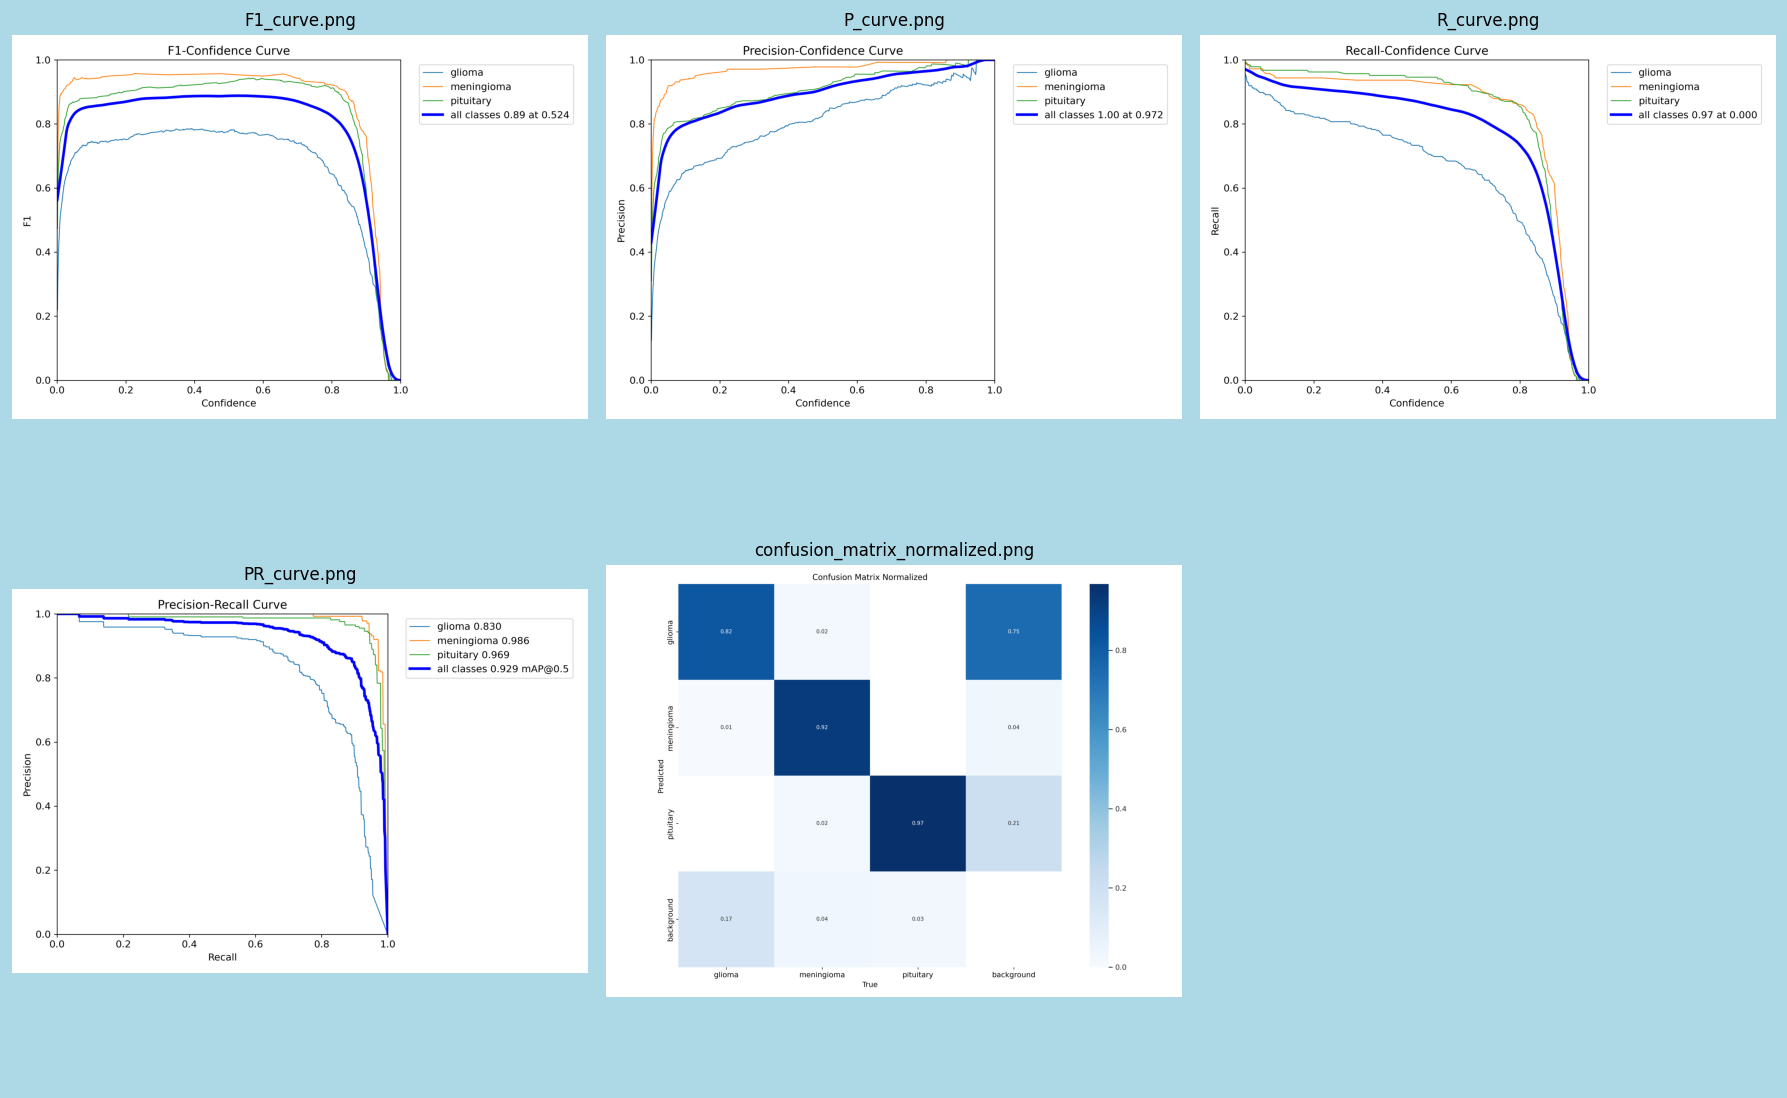

In [9]:
def display_images_in_frame_with_background(post_training_files_path, image_files, background_color='lightgray'):
    # Calculate grid size (rows and columns)
    num_images = len(image_files)
    cols = 3  # Number of columns (you can adjust this as needed)
    rows = (num_images + cols - 1) // cols  # Calculate the number of rows needed
    
    # Set up the subplot grid
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), dpi=120)
    fig.patch.set_facecolor(background_color)  # Set the figure background color
    axes = axes.flatten()  # Flatten to easily index
    
    for i, image_file in enumerate(image_files):
        image_path = os.path.join(post_training_files_path, image_file)
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        axes[i].imshow(img)
        axes[i].axis('off')  # Turn off axis
        axes[i].set_title(image_file, fontsize=10, color='black')  # Add title with black text
    
    # Turn off unused subplots if any
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.show()

# List of image files to display
image_files = [
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
    'PR_curve.png',
    'confusion_matrix_normalized.png',

]

# Path to the directory containing the images
post_training_files_path = '/kaggle/working/runs/detect/train'

# Display the images with a background color
display_images_in_frame_with_background(post_training_files_path, image_files, background_color='lightblue')


<div style="color:white;display:fill;border-radius:8px;
            background-color:#03112A;font-size:150%;
            letter-spacing:1.0px;background-image: url(https://i.imgur.com/GVd0La1.png)">
    <p style="padding: 8px;color:white;"><b><b><span style='color:#e61227''>4.3 |</span></b> Inference Model on Unseen Images </b></p>
</div>


0: 640x640 1 glioma, 6.1ms
Speed: 1.8ms preprocess, 6.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 meningioma, 6.5ms
Speed: 2.2ms preprocess, 6.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 pituitary, 9.1ms
Speed: 2.3ms preprocess, 9.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 meningioma, 6.6ms
Speed: 2.3ms preprocess, 6.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 glioma, 6.5ms
Speed: 2.2ms preprocess, 6.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 glioma, 6.6ms
Speed: 2.2ms preprocess, 6.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 pituitary, 6.3ms
Speed: 2.9ms preprocess, 6.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 meningioma, 6.1ms
Speed: 1.9ms preprocess, 6.1ms inference, 1.2ms postprocess per image at shape (1, 3, 

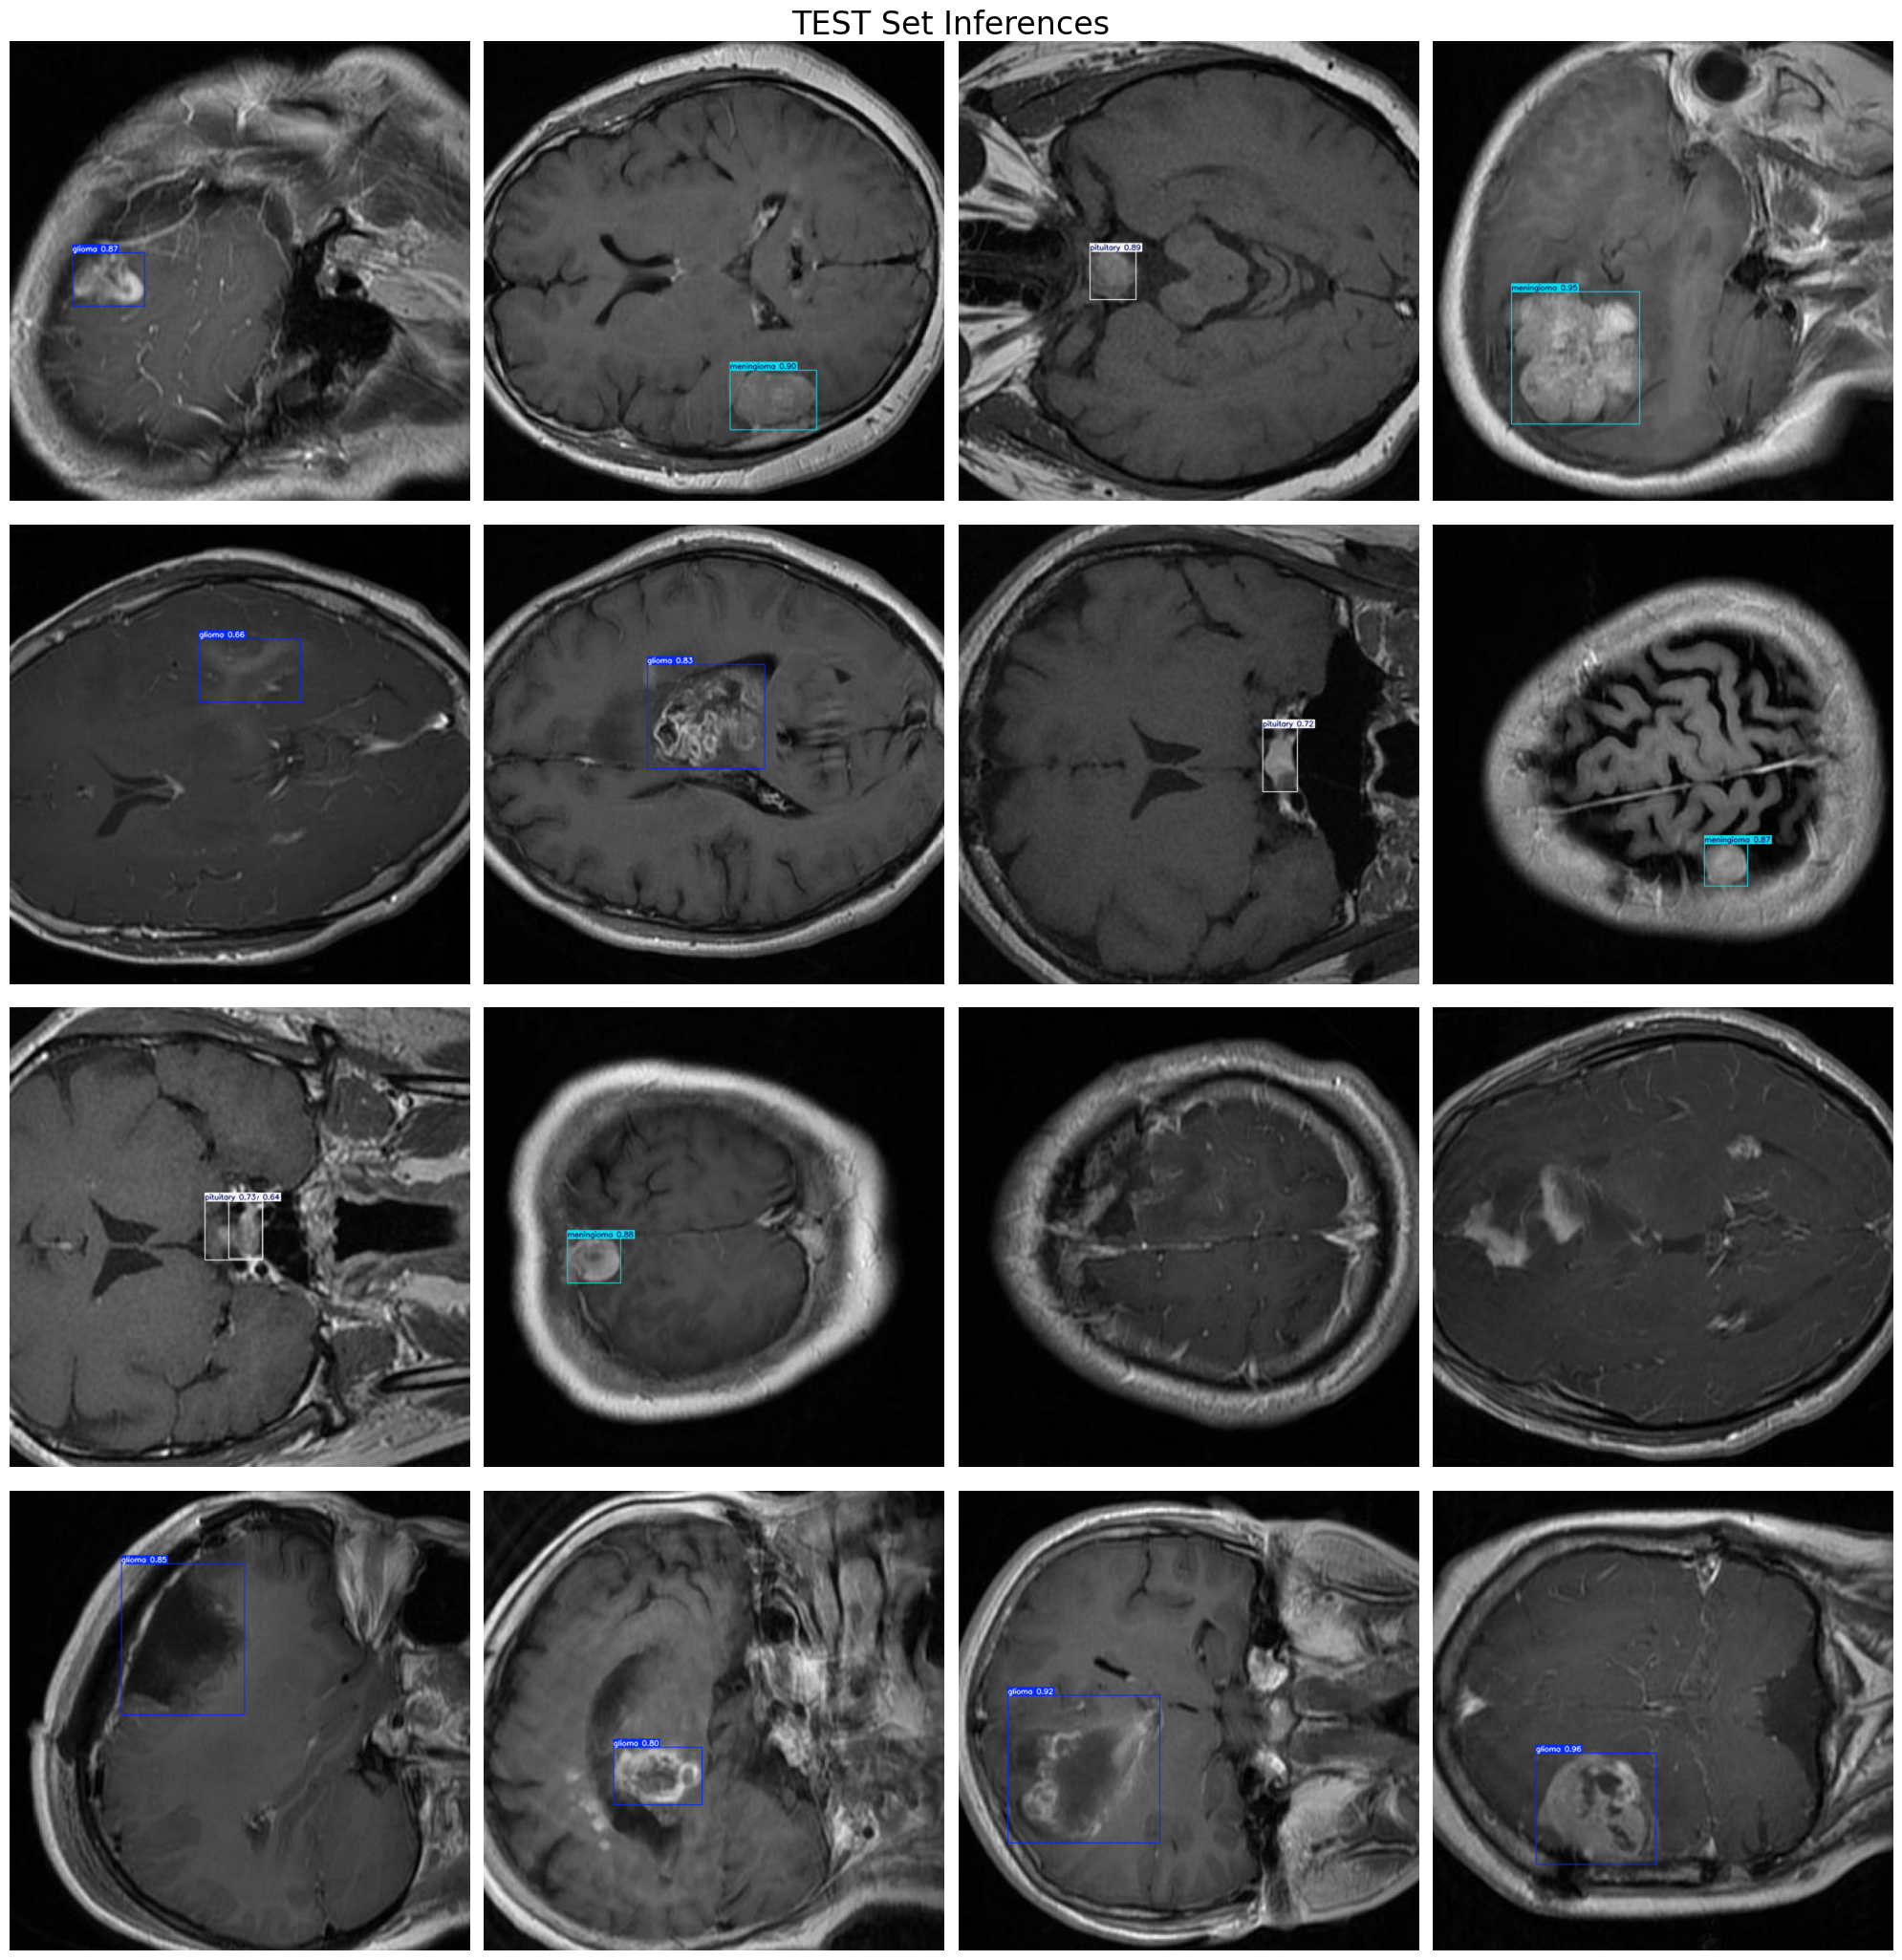

In [11]:
# Validation of Model by TestSet

# Normalization function
def normalize_image(image):
    return image / 255.0

# Image resizing function
def resize_image(image, size=(640, 640)):
    return cv2.resize(image, size)

# Path to validation images
dataset_path = '/kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8'  # Place your dataset path here
valid_images_path = os.path.join(dataset_path, 'test', 'images')

# List of all jpg images in the directory
image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]

# Check if there are images in the directory
if len(image_files) > 0:
    # Select 9 images at equal intervals
    num_images = len(image_files)
    step_size = max(1, num_images // 16)  # Ensure the interval is at least 1
    selected_images = [image_files[i] for i in range(0, num_images, step_size)]

    # Prepare subplots
    fig, axes = plt.subplots(4, 4, figsize=(20, 21))
    fig.suptitle('TEST Set Inferences', fontsize=24)

    for i, ax in enumerate(axes.flatten()):
        if i < len(selected_images):
            image_path = os.path.join(valid_images_path, selected_images[i])
            
            # Load image
            image = cv2.imread(image_path)
            
            # Check if the image is loaded correctly
            if image is not None:
                # Resize image
                resized_image = resize_image(image, size=(640, 640))
                # Normalize image
                normalized_image = normalize_image(resized_image)
                
                # Convert the normalized image to uint8 data type
                normalized_image_uint8 = (normalized_image * 255).astype(np.uint8)
                
                # Predict with the model
                results = best_model.predict(source=normalized_image_uint8, imgsz=640, conf=0.5)
                
                # Plot image with labels
                annotated_image = results[0].plot(line_width=1)
                annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
                ax.imshow(annotated_image_rgb)
            else:
                print(f"Failed to load image {image_path}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()
